# Standalone DAPO Training and Evaluation

Open **this notebook only** in Colab, choose a BF16-capable GPU, and run cells in order. The original training notebook does not need to be open or running.

This notebook reads your existing `Qwen3-1.7B-Base` SFT adapter and saved training/test data from Drive. It embeds the new DAPO runner, so **you do not need to upload train_dapo.py separately**. Your existing `pipeline.py`, `monitoring.py`, and requirements remain in the original project directory.

Defaults: 64 DAPO optimizer updates, four completions per question, two updates per accepted rollout group, learning rate 5e-6, and the same saved 64 test questions. Bounded dynamic sampling, asymmetric clipping, DAPO loss, and a soft overlong penalty are enabled. No teacher download or SFT retraining is needed. Original SFT/GRPO artifacts are preserved.

This is a single-GPU adaptation, not an exact large-scale paper reproduction. Generation cost can exceed the previous GRPO run because rejected groups still consume compute. No accuracy improvement is guaranteed. The notebook and script have passed local syntax/helper checks, but GPU training has not been tested locally.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time, subprocess
from pathlib import Path

# Change only these paths if your files are stored elsewhere.
PROJECT = Path('/content/drive/MyDrive/qwen3_1p7b_128_en')
ROOT = PROJECT/'runs'/'ds8b_qwen1p7b_128_001'
RUN_NAME = 'dapo_001'
STEPS = 64
LEARNING_RATE = 5e-6
ITERATIONS = 2
RL_TOKENS, EVAL_TOKENS = 2048, 2048
SOFT_WINDOW, PENALTY_WEIGHT = 512, 1.0
MAX_RESAMPLES = 16
SEED = 42
STUDENT_CACHE = Path('/content/qwen1p7b_student_cache')

# auto: start, resume the latest checkpoint, or evaluate a completed run.
# eval-only: evaluate an already completed run without training.
MODE = 'auto'

assert MODE in {'auto', 'eval-only'}
required = [PROJECT/'pipeline.py', PROJECT/'monitoring.py', PROJECT/'requirements.txt',
            ROOT/'manifest.json', ROOT/'sft'/'final'/'adapter_config.json',
            ROOT/'sft'/'final'/'adapter_model.safetensors', ROOT/'data'/'rl.jsonl',
            ROOT/'data'/'test_gsm8k.jsonl']
missing = [str(p) for p in required if not p.exists()]
assert not missing, 'Required existing files were not found:\n'+'\n'.join(missing)
os.chdir(PROJECT)
OUT = ROOT/'dapo'/RUN_NAME
print('Existing SFT adapter:', ROOT/'sft'/'final')
print('New DAPO artifacts:', OUT)
print('This notebook does not regenerate teacher data or retrain SFT.')


Mounted at /content/drive
Existing SFT adapter: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/sft/final
New DAPO artifacts: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/dapo/dapo_001
This notebook does not regenerate teacher data or retrain SFT.


## Stream commands and check dependencies

Output is streamed to the cell instead of being hidden until a subprocess finishes. If the known Colab dependency conflicts occur, the optional repair removes unused Gradio/Diffusers packages, installs Jedi, and aligns gcsfs/fsspec with the existing project. It does not delete model caches or Drive data. Disable the repair flag if you need to manage these packages yourself. The runner requires exactly TRL 0.23.1.


In [2]:
def stream_command(command, env=None, logfile=None):
    print('Running:', ' '.join(map(str, command)), flush=True)
    handle = open(logfile, 'a', encoding='utf-8') if logfile else None
    proc = subprocess.Popen(list(map(str, command)), cwd=PROJECT, env=env,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1)
    try:
        for line in proc.stdout:
            print(line, end='', flush=True)
            if handle:
                handle.write(line)
                handle.flush()
        code = proc.wait()
        if code:
            raise RuntimeError(f'Command failed with exit code {code}. Read the output above. Log: {logfile}')
    except BaseException:
        if proc.poll() is None:
            proc.terminate()
            try:
                proc.wait(timeout=20)
            except subprocess.TimeoutExpired:
                proc.kill()
                proc.wait()
        raise
    finally:
        if handle:
            handle.close()

REPAIR_KNOWN_COLAB_CONFLICTS = True
stream_command([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT/'requirements.txt')])
check = subprocess.run([sys.executable, '-m', 'pip', 'check'],
                       capture_output=True, text=True)
print(check.stdout, check.stderr)
if check.returncode:
    repair = PROJECT/'repair_colab.py'
    if REPAIR_KNOWN_COLAB_CONFLICTS and repair.exists():
        stream_command([sys.executable, '-u', str(repair)])
    else:
        raise RuntimeError('Dependency conflicts remain. Inspect pip check output before proceeding.')
stream_command([sys.executable, '-m', 'pip', 'check'])
stream_command([sys.executable, '-c',
    'import importlib.metadata as m; from transformers import Trainer; from peft import PeftModel; '
    'from trl import GRPOTrainer; assert m.version("trl")=="0.23.1"; print("Training imports OK")'])


Running: /usr/bin/python3 -m pip install -r /content/drive/MyDrive/qwen3_1p7b_128_en/requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 148.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 564.6/564.6 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 503.6/503.6 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━

## Check the GPU and saved data

If Colab requests a session restart after installation, restart the session and rerun this notebook from the mount/configuration cell. Do not delete the runtime. Downloading the student base model may still be needed if its temporary cache was lost; the teacher is never loaded.


In [3]:
stream_command(['nvidia-smi'])
import torch, shutil
assert torch.cuda.is_available(), 'Select a GPU runtime.'
assert torch.cuda.is_bf16_supported(), 'This profile requires BF16 support.'
print('GPU:', torch.cuda.get_device_name())
print('GPU VRAM GiB:', round(torch.cuda.get_device_properties(0).total_memory/2**30, 2))
print('Free disk GiB:', round(shutil.disk_usage('/content').free/2**30, 2))
for name in ['rl', 'test_gsm8k']:
    with (ROOT/'data'/f'{name}.jsonl').open() as f:
        n = sum(bool(line.strip()) for line in f)
    print(name, 'questions:', n)


Running: nvidia-smi
Sun Oct 18 23:07:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   45C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------

## Materialize the embedded DAPO runner

This cell writes the embedded English Python script into a temporary Colab directory. It does not replace any original project script or model. Existing project modules are located through PYTHONPATH.


In [4]:
DAPO_SOURCE = '"""Single-GPU DAPO experiment from an existing project SFT LoRA adapter.\n\nRequires pipeline.py, monitoring.py, and exactly trl==0.23.1. No teacher needed.\nThis small-batch implementation includes bounded dynamic group sampling,\ntoken-normalized DAPO loss, asymmetric clipping, and soft overlong rewards.\nIt is not an exact reproduction of the large-scale DAPO paper\'s setup.\n"""\nimport argparse\nimport copy\nimport csv\nimport gc\nimport hashlib\nimport importlib.metadata\nimport json\nimport math\nimport os\nimport random\nimport time\nfrom pathlib import Path\n\nfrom pipeline import STUDENT, correct, extract, numeric, prompt, read, load_model, meta\nfrom monitoring import Progress, training_callback\n\n\ndef soft_penalty(length, limit, window, weight):\n    return -weight * min(1., max(0., (length-(limit-window))/window))\n\n\ndef informative_group(correctness, active):\n    values = [c for c, keep in zip(correctness, active) if keep]\n    return len(values) >= 2 and min(values) < max(values)\n\n\ndef digest(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for chunk in iter(lambda: f.read(1024*1024), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef validate(a):\n    if not 0 < a.soft_window <= a.rl_tokens:\n        raise ValueError(\'soft-window must be in (0, rl-tokens].\')\n    if a.iterations < 1 or a.max_resamples < 0 or a.penalty_weight < 0:\n        raise ValueError(\'Invalid iterations, max-resamples, or penalty-weight.\')\n    if a.steps <= 0 or a.steps % a.iterations:\n        raise ValueError(\'steps must be positive and divisible by iterations.\')\n    if not a.run_name or Path(a.run_name).name != a.run_name or a.run_name in {\'.\', \'..\'}:\n        raise ValueError(\'run-name must be a simple directory name.\')\n    source = a.root/\'sft\'/\'final\'\n    for path in [source/\'adapter_config.json\', source/\'adapter_model.safetensors\',\n                 a.root/\'data\'/\'rl.jsonl\', a.root/\'data\'/\'test_gsm8k.jsonl\']:\n        if not path.exists():\n            raise FileNotFoundError(path)\n    rl = read(a.root/\'data\'/\'rl.jsonl\')\n    test = read(a.root/\'data\'/\'test_gsm8k.jsonl\')\n    if not rl or not test:\n        raise ValueError(\'RL and test sets must be nonempty.\')\n    if len({r[\'id\'] for r in test}) != len(test):\n        raise ValueError(\'Duplicate test IDs.\')\n    if {r[\'id\'] for r in rl} & {r[\'id\'] for r in test}:\n        raise ValueError(\'RL/test overlap detected.\')\n    if importlib.metadata.version(\'trl\') != \'0.23.1\':\n        raise RuntimeError(\'This subclass is validated against TRL 0.23.1 source only. Install project requirements.\')\n    return source, rl, test\n\n\ndef settings(a, source):\n    return {\'algorithm\': \'bounded-single-group-DAPO\', \'student\': STUDENT,\n            \'model_revision\': meta(a.root)[\'model_revisions\'][STUDENT],\n            \'sft_adapter_sha256\': digest(source/\'adapter_model.safetensors\'),\n            \'sft_config_sha256\': digest(source/\'adapter_config.json\'),\n            \'rl_sha256\': digest(a.root/\'data\'/\'rl.jsonl\'),\n            \'test_sha256\': digest(a.root/\'data\'/\'test_gsm8k.jsonl\'),\n            \'steps\': a.steps, \'learning_rate\': a.learning_rate,\n            \'rl_tokens\': a.rl_tokens, \'eval_tokens\': a.eval_tokens,\n            \'num_generations\': 4, \'gradient_accumulation_steps\': 4,\n            \'num_iterations\': a.iterations, \'temperature\': .8, \'top_p\': .95,\n            \'epsilon\': .2, \'epsilon_high\': .28, \'beta\': 0., \'loss_type\': \'dapo\',\n            \'soft_window\': a.soft_window, \'penalty_weight\': a.penalty_weight,\n            \'max_resamples\': a.max_resamples, \'seed\': a.seed, \'trl\': \'0.23.1\'}\n\n\ndef train(a, source, rows, out):\n    import torch\n    from datasets import Dataset\n    from transformers import set_seed\n    from trl import GRPOConfig, GRPOTrainer\n    set_seed(a.seed)\n    stats = {\'sampled_groups\': 0, \'rejected_groups\': 0, \'accepted_groups\': 0,\n             \'generated_completions\': 0, \'generated_tokens\': 0}\n    if a.resume:\n        # Counts are an upper bound if unsaved work was sampled after the resumed checkpoint.\n        old = out/\'sampling_totals.json\'\n        if old.exists():\n            stats.update(json.loads(old.read_text()))\n        print(\'[dapo] Resume: sampling totals may include work after the resumed checkpoint.\', flush=True)\n    pool = [{\'prompt\': prompt(r[\'question\']), \'answer\': r[\'answer\'], \'question_id\': r[\'id\']} for r in rows]\n    latest = {}\n\n    def dapo_reward(completions, answer, completion_ids, **kwargs):\n        texts = [c if isinstance(c, str) else c[0][\'content\'] for c in completions]\n        scores = [float(correct(text, gold)) for text, gold in zip(texts, answer)]\n        lengths = [len(ids) for ids in completion_ids]\n        penalties = [soft_penalty(n, a.rl_tokens, a.soft_window, a.penalty_weight) for n in lengths]\n        latest.update(correctness=scores, lengths=lengths, penalties=penalties)\n        return [score+penalty for score, penalty in zip(scores, penalties)]\n\n    class DAPOTrainer(GRPOTrainer):\n        def _generate_and_score_completions(self, inputs):\n            if self.accelerator.num_processes != 1 or len(inputs) != 4:\n                raise RuntimeError(\'This dynamic sampler supports one GPU and exactly one group of four completions.\')\n            if not self.model.training:\n                return super()._generate_and_score_completions(inputs)\n            sampler = random.Random(a.seed+1009*self.state.global_step)\n            candidates = list(range(len(pool)))\n            sampler.shuffle(candidates)\n            current = inputs\n            for attempt in range(a.max_resamples+1):\n                metrics_before = copy.deepcopy(self._metrics[\'train\'])\n                logs_before = copy.deepcopy(self._logs)\n                token_count_before = self.state.num_input_tokens_seen\n                result = super()._generate_and_score_completions(current)\n                raw = latest[\'correctness\']\n                active = (result[\'completion_mask\'].sum(dim=1) > 0).tolist()\n                accepted = informative_group(raw, active)\n                stats[\'sampled_groups\'] += 1\n                stats[\'generated_completions\'] += len(raw)\n                stats[\'generated_tokens\'] += sum(latest[\'lengths\'])\n                stats[\'accepted_groups\' if accepted else \'rejected_groups\'] += 1\n                event = {\'optimizer_step_before_update\': self.state.global_step,\n                         \'resample_index\': attempt, \'accepted\': accepted,\n                         \'question_id\': current[0][\'question_id\'], \'raw_correctness\': raw,\n                         \'lengths\': latest[\'lengths\'], \'soft_penalties\': latest[\'penalties\'],\n                         \'active_completions\': active, \'timestamp\': time.time(), **stats}\n                with (out/\'sampling.jsonl\').open(\'a\', encoding=\'utf-8\') as f:\n                    f.write(json.dumps(event)+\'\\n\')\n                (out/\'sampling_totals.json\').write_text(json.dumps(stats, indent=2), encoding=\'utf-8\')\n                print(f"[dapo sampling] step={self.state.global_step+1}/{a.steps} "\n                      f"attempt={attempt+1}/{a.max_resamples+1} accepted={accepted} "\n                      f"correct={sum(raw):.0f}/4 total_generated_tokens={stats[\'generated_tokens\']}", flush=True)\n                if accepted:\n                    self._metrics[\'train\'][\'dapo/raw_correctness\'].append(sum(raw)/len(raw))\n                    self._metrics[\'train\'][\'dapo/soft_penalty\'].append(sum(latest[\'penalties\'])/len(raw))\n                    self._metrics[\'train\'][\'dapo/resamples\'].append(attempt)\n                    self._metrics[\'train\'][\'dapo/rejection_fraction\'].append(\n                        stats[\'rejected_groups\']/stats[\'sampled_groups\'])\n                    return result\n                # Do not report discarded-group rewards as optimization-batch rewards.\n                self._metrics[\'train\'] = metrics_before\n                self._logs = logs_before\n                self.state.num_input_tokens_seen = token_count_before\n                del result\n                if attempt < a.max_resamples:\n                    index = candidates[attempt % len(candidates)]\n                    current = [dict(pool[index]) for _ in range(4)]\n            raise RuntimeError(\n                \'Dynamic sampling exhausted its retry budget without a mixed-correctness active group. \'\n                \'Training stopped; no zero-signal fallback update was performed. Inspect sampling.jsonl, \'\n                \'truncation, and RL task difficulty. Resume from a saved checkpoint after investigating.\')\n\n    model, tok = load_model(STUDENT, a.root, adapter=source, train=True)\n    model.config.use_cache = False\n    model.enable_input_require_grads()\n    tok.padding_side = \'left\'\n    config = GRPOConfig(\n        output_dir=str(out/\'checkpoints\'), per_device_train_batch_size=1,\n        gradient_accumulation_steps=4, steps_per_generation=4, num_generations=4,\n        num_iterations=a.iterations, max_prompt_length=1024, max_completion_length=a.rl_tokens,\n        learning_rate=a.learning_rate, max_steps=a.steps, bf16=True,\n        gradient_checkpointing=True, gradient_checkpointing_kwargs={\'use_reentrant\': False},\n        loss_type=\'dapo\', epsilon=.2, epsilon_high=.28, beta=0., scale_rewards=\'group\',\n        temperature=.8, top_p=.95, mask_truncated_completions=True, use_vllm=False,\n        logging_steps=1, save_steps=16, save_total_limit=3, report_to=\'none\',\n        disable_tqdm=True, seed=a.seed)\n    (out/\'grpo_config.json\').write_text(config.to_json_string(), encoding=\'utf-8\')\n    print(\'[dapo] Starting from SFT, not the previous GRPO adapter.\', flush=True)\n    print(f\'[dapo] {a.steps} optimizer updates; {a.iterations} updates per sampled group; \'\n          \'dynamic sampling adds variable generation cost.\', flush=True)\n    trainer = DAPOTrainer(model=model, processing_class=tok, args=config,\n                          train_dataset=Dataset.from_list(pool), reward_funcs=dapo_reward,\n                          callbacks=[training_callback(out, \'dapo\')])\n    trainer.train(resume_from_checkpoint=str(a.resume) if a.resume else None)\n    trainer.save_model(str(out/\'final\'))\n    tok.save_pretrained(out/\'final\')\n    (out/\'TRAINING_COMPLETE.json\').write_text(json.dumps({\'global_step\': trainer.state.global_step,\n                                                        \'timestamp\': time.time()}), encoding=\'utf-8\')\n    del trainer, model, tok\n    gc.collect()\n    torch.cuda.empty_cache()\n\n\ndef summarize(rows, stage, budget):\n    n = len(rows)\n    parsed = [extract(r[\'text\']) for r in rows]\n    answers = [correct(r[\'text\'], r[\'answer\']) for r in rows]\n    lengths = sorted(r[\'tokens\'] for r in rows)\n    return {\'stage\': stage, \'split\': \'test_gsm8k\', \'n\': n, \'eval_budget\': budget,\n            \'correct_count\': sum(answers), \'accuracy\': sum(answers)/n,\n            \'answer_parse_rate\': sum(x is not None and numeric(x) is not None for x in parsed)/n,\n            \'mean_tokens\': sum(lengths)/n, \'p95_tokens\': lengths[math.ceil(.95*n)-1],\n            \'mean_seconds\': sum(r[\'seconds\'] for r in rows)/n,\n            \'budget_hit_rate\': sum(r[\'budget_hit\'] for r in rows)/n}\n\n\ndef evaluate(a, questions, out):\n    import torch\n    from transformers import set_seed\n    set_seed(a.seed)\n    if not (out/\'TRAINING_COMPLETE.json\').exists():\n        raise RuntimeError(\'No completed DAPO run found. Finish training before evaluating final.\')\n    predictions = out/\'test_predictions.jsonl\'\n    results = read(predictions) if predictions.exists() else []\n    done = {r[\'id\'] for r in results}\n    progress = Progress(out, \'eval_dapo\', len(questions), initial=len(done))\n    progress.update(len(done))\n    if len(done) < len(questions):\n        model, tok = load_model(STUDENT, a.root, adapter=out/\'final\')\n        model.eval()\n        with predictions.open(\'a\', encoding=\'utf-8\') as f:\n            for q in questions:\n                if q[\'id\'] in done:\n                    continue\n                inputs = tok(prompt(q[\'question\']), add_special_tokens=False, return_tensors=\'pt\').to(model.device)\n                torch.cuda.synchronize()\n                start = time.perf_counter()\n                with torch.inference_mode():\n                    ids = model.generate(**inputs, do_sample=False, max_new_tokens=a.eval_tokens,\n                                         pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)\n                torch.cuda.synchronize()\n                new = ids[0, inputs.input_ids.shape[1]:]\n                text = tok.decode(new, skip_special_tokens=True)\n                row = {**q, \'text\': text, \'tokens\': len(new), \'seconds\': time.perf_counter()-start,\n                       \'correct\': correct(text, q[\'answer\']),\n                       \'budget_hit\': len(new) >= a.eval_tokens and int(new[-1]) != tok.eos_token_id}\n                f.write(json.dumps(row, ensure_ascii=False)+\'\\n\')\n                f.flush()\n                done.add(q[\'id\'])\n                results.append(row)\n                progress.update(len(done), correct=row[\'correct\'], tokens=row[\'tokens\'])\n        del model, tok\n        gc.collect()\n        torch.cuda.empty_cache()\n    summary = summarize(results, \'dapo\', a.eval_tokens)\n    (out/\'test_summary.json\').write_text(json.dumps(summary, indent=2), encoding=\'utf-8\')\n    comparison = []\n    gold = {q[\'id\']: (q[\'question\'], q[\'answer\']) for q in questions}\n    for stage in [\'sft\', \'grpo\']:\n        path = a.root/\'eval\'/f\'{stage}_test_gsm8k_{a.eval_tokens}.jsonl\'\n        if path.exists():\n            old = read(path)\n            if len(old) == len(gold) and {r[\'id\']: (r[\'question\'], r[\'answer\']) for r in old} == gold:\n                comparison.append(summarize(old, stage, a.eval_tokens))\n            else:\n                print(f\'[comparison] Skipping {stage}: saved test questions do not match.\')\n    comparison.append(summary)\n    report = [{\'stage\': r[\'stage\'], \'n\': r[\'n\'], \'correct\': r[\'correct_count\'],\n               \'accuracy_percent\': round(100*r[\'accuracy\'], 2),\n               \'answer_parse_percent\': round(100*r[\'answer_parse_rate\'], 2),\n               \'mean_tokens\': round(r[\'mean_tokens\'], 1), \'mean_seconds\': round(r[\'mean_seconds\'], 2),\n               \'budget_hit_percent\': round(100*r[\'budget_hit_rate\'], 2)} for r in comparison]\n    with (out/\'comparison.csv\').open(\'w\', newline=\'\', encoding=\'utf-8\') as f:\n        writer = csv.DictWriter(f, fieldnames=list(report[0]))\n        writer.writeheader()\n        writer.writerows(report)\n    print(\'\\nFinal comparison (saved SFT/GRPO predictions, new DAPO predictions):\', flush=True)\n    for r in report:\n        print(json.dumps(r), flush=True)\n    print(f"\\nDAPO test accuracy: {summary[\'correct_count\']}/{summary[\'n\']} = {100*summary[\'accuracy\']:.2f}%")\n    print(\'Artifacts:\', out)\n    print(\'Accuracy means exact-answer correctness, not classification precision.\')\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--root\', type=Path, required=True, help=\'Existing experiment containing sft/final and data/\')\n    p.add_argument(\'--run-name\', default=\'dapo_001\')\n    p.add_argument(\'--steps\', type=int, default=64)\n    p.add_argument(\'--learning-rate\', type=float, default=5e-6,\n                   help=\'Match the previous GRPO baseline; use a different run-name for a LR ablation.\')\n    p.add_argument(\'--iterations\', type=int, default=2,\n                   help=\'Two policy updates per sampled group so clipping can affect reused rollouts.\')\n    p.add_argument(\'--rl-tokens\', type=int, default=2048)\n    p.add_argument(\'--eval-tokens\', type=int, default=2048)\n    p.add_argument(\'--soft-window\', type=int, default=512)\n    p.add_argument(\'--penalty-weight\', type=float, default=1.)\n    p.add_argument(\'--max-resamples\', type=int, default=16)\n    p.add_argument(\'--seed\', type=int, default=42)\n    p.add_argument(\'--resume\', type=Path)\n    p.add_argument(\'--eval-only\', action=\'store_true\')\n    p.add_argument(\'--train-only\', action=\'store_true\')\n    a = p.parse_args()\n    if a.eval_only and a.train_only:\n        p.error(\'Choose at most one of eval-only and train-only.\')\n    if int(os.environ.get(\'WORLD_SIZE\', \'1\')) != 1:\n        p.error(\'Use one GPU; do not launch through multi-process accelerate.\')\n    source, rl, questions = validate(a)\n    out = a.root/\'dapo\'/a.run_name\n    if a.resume and not a.resume.resolve().is_relative_to((out/\'checkpoints\').resolve()):\n        p.error(\'Resume only from this DAPO run, not an SFT or old GRPO checkpoint.\')\n    out.mkdir(parents=True, exist_ok=True)\n    metadata = settings(a, source)\n    config_path = out/\'experiment.json\'\n    if config_path.exists() and json.loads(config_path.read_text()) != metadata:\n        p.error(\'Saved run settings differ. Choose a new run-name.\')\n    config_path.write_text(json.dumps(metadata, indent=2), encoding=\'utf-8\')\n    if not a.eval_only:\n        if (out/\'TRAINING_COMPLETE.json\').exists():\n            p.error(\'Training already completed. Use --eval-only or a new run-name.\')\n        if any((out/\'checkpoints\').glob(\'checkpoint-*\')) and not a.resume:\n            p.error(\'Checkpoints already exist. Resume explicitly or use a new run-name.\')\n        if (out/\'sampling.jsonl\').exists() and not a.resume:\n            p.error(\'Sampling from an earlier attempt exists. Use a new run-name or resume an existing checkpoint.\')\n        train(a, source, rl, out)\n    if not a.train_only:\n        evaluate(a, questions, out)\n\n\nif __name__ == \'__main__\':\n    main()\n'
SCRIPT_DIR = Path('/content/dapo_standalone_runner')
SCRIPT_DIR.mkdir(parents=True, exist_ok=True)
SCRIPT = SCRIPT_DIR/'train_dapo.py'
compile(DAPO_SOURCE, str(SCRIPT), 'exec')
SCRIPT.write_text(DAPO_SOURCE, encoding='utf-8')
print('Embedded runner ready:', SCRIPT)


Embedded runner ready: /content/dapo_standalone_runner/train_dapo.py


## Train DAPO and test the saved 64-question subset

Training starts from the saved SFT adapter. Console output reports group sampling/rejections, optimizer progress, reward statistics, elapsed time, ETA, and GPU memory. Checkpoints are saved every 16 updates. A complete run automatically proceeds to test evaluation and prints accuracy and a comparison with available saved SFT/GRPO predictions.

Auto mode resumes the latest checkpoint when possible. If a prior attempt stopped before its first checkpoint, choose a new RUN_NAME to keep logs separate. Changed hyperparameters require a new RUN_NAME. The test set is not used to select training groups or checkpoints.


In [5]:
env = dict(os.environ)
env['HF_HOME'] = str(STUDENT_CACHE)
env['PYTHONPATH'] = str(PROJECT)+os.pathsep+env.get('PYTHONPATH', '')
env['TOKENIZERS_PARALLELISM'] = 'false'
env['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
env['PYTHONUNBUFFERED'] = '1'

command = [sys.executable, '-u', str(SCRIPT), '--root', str(ROOT), '--run-name', RUN_NAME,
           '--steps', str(STEPS), '--learning-rate', str(LEARNING_RATE),
           '--iterations', str(ITERATIONS), '--rl-tokens', str(RL_TOKENS),
           '--eval-tokens', str(EVAL_TOKENS), '--soft-window', str(SOFT_WINDOW),
           '--penalty-weight', str(PENALTY_WEIGHT), '--max-resamples', str(MAX_RESAMPLES),
           '--seed', str(SEED)]

if MODE == 'eval-only' or (OUT/'TRAINING_COMPLETE.json').exists():
    command.append('--eval-only')
else:
    checkpoints = sorted((OUT/'checkpoints').glob('checkpoint-*'),
                         key=lambda p: int(p.name.split('-')[-1]))
    if checkpoints:
        command += ['--resume', str(checkpoints[-1])]
        print('Resuming:', checkpoints[-1])
    elif (OUT/'sampling.jsonl').exists():
        raise RuntimeError('A partial attempt exists without a checkpoint. Select a new RUN_NAME in the configuration cell.')

console_dir = ROOT/'dapo_launcher_logs'
console_dir.mkdir(parents=True, exist_ok=True)
logfile = console_dir/f'{RUN_NAME}_{time.time_ns()}.console.log'
print('Console log:', logfile)
stream_command(command, env=env, logfile=logfile)


Console log: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/dapo_launcher_logs/dapo_001_1792364889094759992.console.log
Running: /usr/bin/python3 -u /content/dapo_standalone_runner/train_dapo.py --root /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001 --run-name dapo_001 --steps 64 --learning-rate 5e-06 --iterations 2 --rl-tokens 2048 --eval-tokens 2048 --soft-window 512 --penalty-weight 1.0 --max-resamples 16 --seed 42
I0000 00:00:1792364900.669135    7862 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792364900.738078    7862 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operation

## Results and training curves

Accuracy means exact-answer correctness, not classification precision. Parse rate is shown separately. The baseline rows reuse historical predictions on matching test questions. A 64-question score changes by about 1.56 percentage points per answer; do not infer a stable improvement from a small change alone.


In [6]:
import pandas as pd
from IPython.display import display
report = OUT/'comparison.csv'
if report.exists():
    display(pd.read_csv(report))
else:
    print('No final report yet. Training/evaluation must complete first.')
summary = OUT/'test_summary.json'
if summary.exists():
    result = json.loads(summary.read_text())
    print(f"DAPO accuracy: {result['correct_count']}/{result['n']} = {100*result['accuracy']:.2f}%")
print('Final DAPO adapter:', OUT/'final')
print('Predictions:', OUT/'test_predictions.jsonl')
print('Training progress:', OUT/'logs'/'dapo_metrics.jsonl')


,stage,n,correct,accuracy_percent,answer_parse_percent,mean_tokens,mean_seconds,budget_hit_percent
0,sft,64,50,78.12,96.88,300.4,22.13,4.69
1,grpo,64,47,73.44,95.31,349.5,25.76,4.69
2,dapo,64,49,76.56,96.88,563.8,40.90,15.62


DAPO accuracy: 49/64 = 76.56%
Final DAPO adapter: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/dapo/dapo_001/final
Predictions: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/dapo/dapo_001/test_predictions.jsonl
Training progress: /content/drive/MyDrive/qwen3_1p7b_128_en/runs/ds8b_qwen1p7b_128_001/dapo/dapo_001/logs/dapo_metrics.jsonl


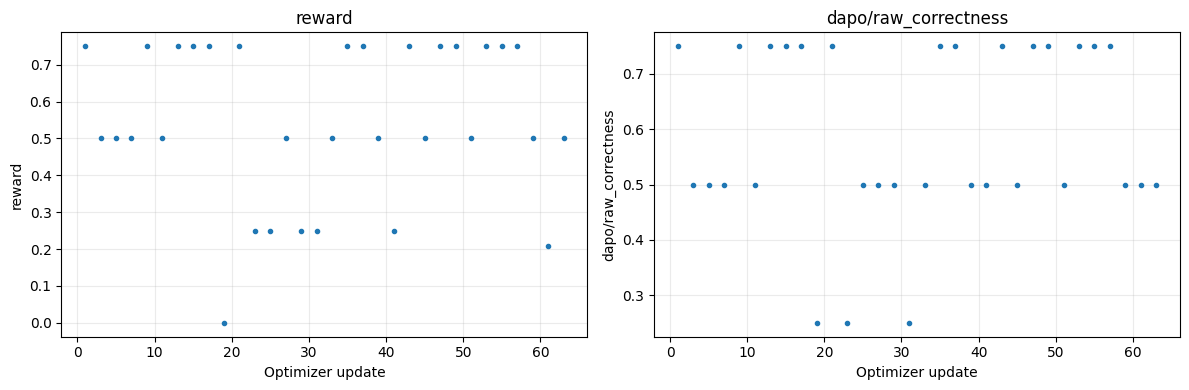

Generation accounting (including rejected groups):
{
  "sampled_groups": 48,
  "rejected_groups": 16,
  "accepted_groups": 32,
  "generated_completions": 192,
  "generated_tokens": 99818
}


In [7]:
import matplotlib.pyplot as plt
metrics_file = OUT/'logs'/'dapo_metrics.jsonl'
if metrics_file.exists():
    rows = [json.loads(line) for line in metrics_file.read_text().splitlines() if line.strip()]
    points = [r for r in rows if r.get('event') == 'train_log']
    if points:
        frame = pd.DataFrame(points).drop_duplicates('current', keep='last').sort_values('current')
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        for ax, metric in zip(axes, ['reward', 'dapo/raw_correctness']):
            if metric in frame:
                ax.plot(frame['current'], frame[metric], marker='.')
            ax.set(title=metric, xlabel='Optimizer update', ylabel=metric)
            ax.grid(alpha=.25)
        fig.tight_layout()
        fig.savefig(OUT/'training_curves.png', dpi=160)
        plt.show()
totals = OUT/'sampling_totals.json'
if totals.exists():
    print('Generation accounting (including rejected groups):')
    print(json.dumps(json.loads(totals.read_text()), indent=2))
